In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import verification_hooks as _verification_hooks
_verification_hooks.install_hooks()

**Logistic Regression + T1: degree-2 polynomial features (2,774 columns)**

This notebook implements splits and preprocessing, a fresh sklearn pipeline for each of six C values, train/validation scoring, validation curves, best-setting selection, confusion matrix, attack-type error analysis and CSV export.

Training keeps 24,000 rows and validation keeps 6,000. Both are mapped from 41 raw model-input columns to 73 shared preprocessed features and then to 2,774 polynomial features.
The official test split is not loaded or scored here.

The raw split CSVs come from `preprocessing.ipynb`; each model calls the shared `build_preprocessor()` itself. No in-memory variables from another notebook are required. This is T1 across **all 73 inputs**.

**The feature map and logistic-regression objective**

Let $u=T(x)\in\mathbb{R}^{73}$ be the shared preprocessed row. The second-order
feature map includes the original terms, their squares and pairwise products:

$$\phi_2(u)=[u_1,\ldots,u_{73},u_1^2,u_1u_2,\ldots,u_{73}^2].$$

With `PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)`,

$$d=\binom{73+2}{2}-1
=73+73+\binom{73}{2}
=73+73+2628=2774.$$

There is no constant bias column because logistic regression supplies its own
intercept. After polynomial expansion, standardize each column using training
statistics: $z_j=(\phi_j-\mu_j)/s_j$. Constant columns map to zero.

Logistic regression estimates $p=P(y=1\mid x)=\sigma(w^\top z+b)$, with
$\sigma(t)=1/(1+e^{-t})$, and minimizes the unweighted L2 objective

$$\sum_{i=1}^{n}[-y_i\log p_i-(1-y_i)\log(1-p_i)]
+\frac{1}{2C}\lVert w\rVert_2^2.$$

This is equivalent to the reference notebook's
$\frac12\lVert w\rVert^2+C\sum_i\ell_i$. Smaller C means stronger shrinkage;
larger C means weaker shrinkage. The `lbfgs` estimator uses L2 by default and does
not penalize its intercept. The model is linear in $z$, but its boundary can be
quadratic in the preprocessed variables $u$.

Sources: [sklearn PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
and [sklearn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

**1. Setup and load the shared train/validation splits**

`load_split()` reads `data/processed/train.csv` or `val.csv`, removes `id`,
`label`, `attack_cat` and redundant `is_ftp_login` from the predictors, and returns
features, target labels and attack-type metadata. `attack_cat` is used only for
error analysis. Run `preprocessing.ipynb` first if those files are absent.

The output prints input shapes and a binary-class count/share table. Assertions
check the 24,000/6,000 sizes, the same feature schema and disjoint source row IDs.
No new sampling is performed, so all six fits are comparable with T0, T2 and T3.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "preprocessing.py").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.preprocessing import RANDOM_STATE, NOT_FEATURES, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = ROOT / "figures"
FIGS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
split_paths = [ROOT / "data" / "processed" / f"{name}.csv" for name in ("train", "val")]
if not all(path.is_file() for path in split_paths):
    raise FileNotFoundError("Run notebook/preprocessing.ipynb to create the shared splits first.")

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
assert X_train.shape == (24_000, 41) and X_val.shape == (6_000, 41)
assert X_train.columns.equals(X_val.columns)
assert X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index)
assert not set(NOT_FEATURES).intersection(X_train.columns)
train_ids = pd.read_csv(split_paths[0], usecols=["id"])["id"]
val_ids = pd.read_csv(split_paths[1], usecols=["id"])["id"]
assert set(train_ids).isdisjoint(val_ids)
print("Raw model inputs — train:", X_train.shape, "validation:", X_val.shape)
print("Row-ID overlap: 0. Official test split not loaded.")

balance = pd.DataFrame({
    "train_count": y_train.value_counts().reindex([0, 1], fill_value=0),
    "val_count": y_val.value_counts().reindex([0, 1], fill_value=0),
}).rename(index={0: "Normal", 1: "Attack"})
balance["train_share"] = balance["train_count"] / len(y_train)
balance["val_share"] = balance["val_count"] / len(y_val)
display(balance.round(4))

Raw model inputs — train: (24000, 41) validation: (6000, 41)
Row-ID overlap: 0. Official test split not loaded.


,train_count,val_count,train_share,val_share
label,,,,
Normal,11559,2890,0.4816,0.4817
Attack,12441,3110,0.5184,0.5183


**2. Verify the second-order transformation**

The diagnostic block fits the shared preprocessor on training only, producing
73 inputs: 35 categorical indicators, 31 log1p-scaled numeric columns and seven
other scaled numeric columns. The fixed feature/category lists come from the
shared EDA decisions; fitted scaling statistics come from training only.

`PolynomialFeatures.fit()` establishes the deterministic powers and column order;
it does not learn means or label-dependent parameters. We check its output count
and transform a few training rows to demonstrate the actual feature map. The table
counts 73 linear, 73 squared and 2,628 pairwise-product columns, and shows named
examples. Full training transformations occur inside each model pipeline below.
We avoid retaining a second full 24,000 × 2,774 dense matrix just for this check.

In [3]:
preview_prep = build_preprocessor().fit(X_train)
Xt_train = preview_prep.transform(X_train)
assert Xt_train.shape == (24_000, 73) and np.isfinite(Xt_train).all()
base_names = preview_prep.get_feature_names_out()
poly_preview = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
poly_preview.fit(Xt_train[:1])
Z_preview = poly_preview.transform(Xt_train[:4])
assert poly_preview.n_output_features_ == 2774
assert Z_preview.shape == (4, 2774) and np.isfinite(Z_preview).all()

powers = poly_preview.powers_
poly_names = poly_preview.get_feature_names_out(base_names)
linear = powers.sum(axis=1) == 1
squared = (powers == 2).any(axis=1)
interactions = (powers == 1).sum(axis=1) == 2
assert (int(linear.sum()), int(squared.sum()), int(interactions.sum())) == (73, 73, 2628)
transformation_summary = pd.DataFrame([
    {"term_type": label, "columns": int(mask.sum()), "examples": list(poly_names[mask][:3])}
    for label, mask in [("Linear", linear), ("Squares", squared), ("Pairwise products", interactions)]
])
print("Shared preprocessing:", Xt_train.shape)
print("Expected full T1 shapes: train (24000, 2774), validation (6000, 2774)")
print("Actual four-row polynomial preview:", Z_preview.shape)
print(f"One float64 training feature matrix: {24_000 * 2774 * 8 / 1024**2:.1f} MiB")
display(transformation_summary)

Shared preprocessing: (24000, 73)
Expected full T1 shapes: train (24000, 2774), validation (6000, 2774)
Actual four-row polynomial preview: (4, 2774)
One float64 training feature matrix: 507.9 MiB


,term_type,columns,examples
0,Linear,73,"[cat__proto_tcp, cat__proto_udp, cat__proto_unas]"
1,Squares,73,"[cat__proto_tcp^2, cat__proto_udp^2, cat__prot..."
2,Pairwise products,2628,"[cat__proto_tcp cat__proto_udp, cat__proto_tcp..."


**Why this representation may help, and what 2,774 means**

Numeric squares allow curved effects; numeric products allow joint effects such
as a combination of outgoing and incoming traffic. A category-by-numeric product
can give, for example, duration a different log-odds slope for HTTP traffic.
These products use the already logged/scaled measurements, not raw units.

Expanding all one-hot columns also creates redundant terms: a binary indicator
squared equals itself, and products of mutually exclusive indicators are zero.
We deliberately retain these columns to match the agreed 2,774-column grid;
2,774 does **not** mean 2,774 independent directions. L2 regularization helps
control redundant coefficients, but does not eliminate redundancy.

The EDA's heavy tails still justify the shared log transform. Squaring and
multiplying can create large ranges again, so we add a training-fitted scaler
after expansion, as in T3. Constant expanded columns become zero. Relative to
T0, this experiment changes both the basis and its final scaling; improvements
cannot be attributed to added features alone.

Greater capacity can improve fit but can also amplify lab-specific TTL patterns
and overfit rare categories. Conflicting labels and overlapping Fuzzers/Normal
features can remain difficult. The curves and attack-type table below assess
these issues without assuming that polynomial features must improve validation.

**3. Build the full sklearn pipeline**

`build(C, max_iter)` returns a new, **unfitted** pipeline:

**shared preprocessing → polynomial degree 2 → StandardScaler → logistic regression**.

It always preserves 2,774 output columns and uses no PCA. Both scalers and the
classifier are fitted only on training rows. Predictions transform validation
with the fitted parameters. The logistic-regression solver is `lbfgs`, with L2
regularization, an intercept, no class reweighting and the default 0.5 probability
threshold, matching the reference design. The initial iteration budget is 2,000.
The optional higher budget below addresses convergence, not a new feature map.

In [4]:
def build(C, max_iter=2000):
    """Return a fresh LR T1 pipeline; C controls L2 strength, not feature count."""
    return make_pipeline(
        build_preprocessor(),
        PolynomialFeatures(degree=2, include_bias=False, interaction_only=False),
        StandardScaler(),
        LogisticRegression(C=C, solver="lbfgs", max_iter=max_iter,
                           class_weight=None, random_state=RANDOM_STATE),
    )

**4. Train six regularization settings**

Use the reference's grid `[0.001, 0.01, 0.1, 1, 10, 100]`. It spans five orders of
magnitude while keeping comparisons with T0/T2/T3 controlled.

| C | Reason to try it |
|---|---|
| 0.001 | Strong shrinkage to constrain the much larger quadratic basis. |
| 0.01 | Relax shrinkage and check whether suppressed interactions become useful. |
| 0.1 | Intermediate regularization balancing flexibility and coefficient size. |
| 1 | Conventional default-C reference, also tested in the other notebooks. |
| 10 | Weak regularization to test whether improved training fit carries to validation. |
| 100 | Weakest regularization in the grid; inspect overfitting, runtime and convergence. |

`evaluate()` fits a pipeline on 24,000 training rows and returns train/validation
precision, recall, F1, FPR, fit time and a convergence flag. Each C gets its own
pipeline. Fits run sequentially to limit peak memory, and the dictionary keeps
only fitted estimator parameters, not six expanded training matrices.

If sklearn reports non-convergence, retry that C with a 4,000- then 8,000-iteration
budget, using the same data, tolerance and C. This decision depends only on the
optimizer warning, not validation performance. The CSV's `fit_time_s` describes
the final attempt; the diagnostic table records attempts and cumulative fit time.
Unconverged final attempts are retained in the six-row CSV and excluded from
best-model selection. Do not interpret an optimizer failure as overfitting.

In [5]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted, optimizer_rows = [], {}, []

for value in GRID:
    cumulative_fit_time = 0.0
    for attempt, budget in enumerate([2000, 4000, 8000], start=1):
        pipe = build(value, max_iter=budget)
        row = evaluate(pipe, "LR", "T1", "C", value, X_train, y_train, X_val, y_val)
        cumulative_fit_time += row["fit_time_s"]
        if row["converged"]:
            break
        print(f"C={value:g}: not converged at max_iter={budget}; "
              + ("retrying with a larger iteration budget." if budget < 8000 else "flagging final result."),
              flush=True)
    classifier = pipe.named_steps["logisticregression"]
    assert classifier.n_features_in_ == 2774
    assert pipe.named_steps["polynomialfeatures"].n_output_features_ == 2774
    assert pipe.named_steps["standardscaler"].n_samples_seen_ == len(X_train)
    assert pipe.named_steps["columntransformer"].named_transformers_["log"].named_steps["standardscaler"].n_samples_seen_ == len(X_train)
    assert pipe.named_steps["columntransformer"].named_transformers_["num"].n_samples_seen_ == len(X_train)
    rows.append(row)
    fitted[value] = pipe
    optimizer_rows.append({
        "C": value, "attempts": attempt, "max_iter": budget,
        "iterations": int(classifier.n_iter_.max()),
        "cumulative_fit_time_s": round(cumulative_fit_time, 2),
        "coefficient_L2_norm": float(np.linalg.norm(classifier.coef_)),
    })
    print(f"C={value:g}: train F1={row['train_f1']:.4f}, val F1={row['val_f1']:.4f}, "
          f"fit time={row['fit_time_s']}s, converged={row['converged']}", flush=True)

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
optimizer_diagnostics = pd.DataFrame(optimizer_rows)
assert len(results) == 6 and results["value"].nunique() == 6
# Save the complete sweep before further analysis, so flags survive any later error.
results.to_csv(RESULTS / "lr_t1_poly2.csv", index=False)
display(results.drop(columns=["model", "transformation", "param"]).round(4))
display(optimizer_diagnostics.round(4))

C=0.001: train F1=0.9191, val F1=0.9163, fit time=1.34s, converged=True


C=0.01: train F1=0.9236, val F1=0.9174, fit time=1.78s, converged=True


C=0.1: train F1=0.9264, val F1=0.9167, fit time=2.22s, converged=True


C=1: train F1=0.9288, val F1=0.9163, fit time=4.11s, converged=True


C=10: train F1=0.9302, val F1=0.9154, fit time=7.23s, converged=True


C=100: train F1=0.9317, val F1=0.9167, fit time=10.25s, converged=True


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8783,0.9637,0.9191,0.1437,0.8773,0.9588,0.9163,0.1443,1.34,True,0.0028
1,0.010,0.8949,0.9543,0.9236,0.1206,0.8900,0.9466,0.9174,0.1260,1.78,True,0.0062
2,0.100,0.9062,0.9477,0.9264,0.1056,0.8997,0.9344,0.9167,0.1121,2.22,True,0.0097
3,1.000,0.9126,0.9456,0.9288,0.0974,0.9034,0.9296,0.9163,0.1069,4.11,True,0.0125
4,10.000,0.9156,0.9453,0.9302,0.0938,0.9051,0.9260,0.9154,0.1045,7.23,True,0.0147
5,100.000,0.9179,0.9459,0.9317,0.0911,0.9050,0.9286,0.9167,0.1048,10.25,True,0.0150


,C,attempts,max_iter,iterations,cumulative_fit_time_s,coefficient_L2_norm
0,0.001,1,2000,57,1.34,0.9012
1,0.010,1,2000,132,1.78,1.8844
2,0.100,1,2000,225,2.22,4.1737
3,1.000,1,2000,514,4.11,10.0589
4,10.000,1,2000,1028,7.23,23.9485
5,100.000,1,2000,1563,10.25,45.7658


**5. Validation curves and interpretation**

`plot_sweep()` uses the same format as T2. The left graph shows train F1 (dashed)
and validation F1 (solid) against logarithmic C. A growing positive gap combined
with worsening validation is consistent with overfitting; similar scores alone
do not prove underfitting. The right graph shows the trade-off among attack
precision, attack recall and normal-traffic FPR at the fixed prediction threshold.

The printed interpretation is computed from this run, rather than copied from
T2. The optimizer table above checks whether differences could reflect convergence
issues; coefficient norm is descriptive and is not used to choose a model.

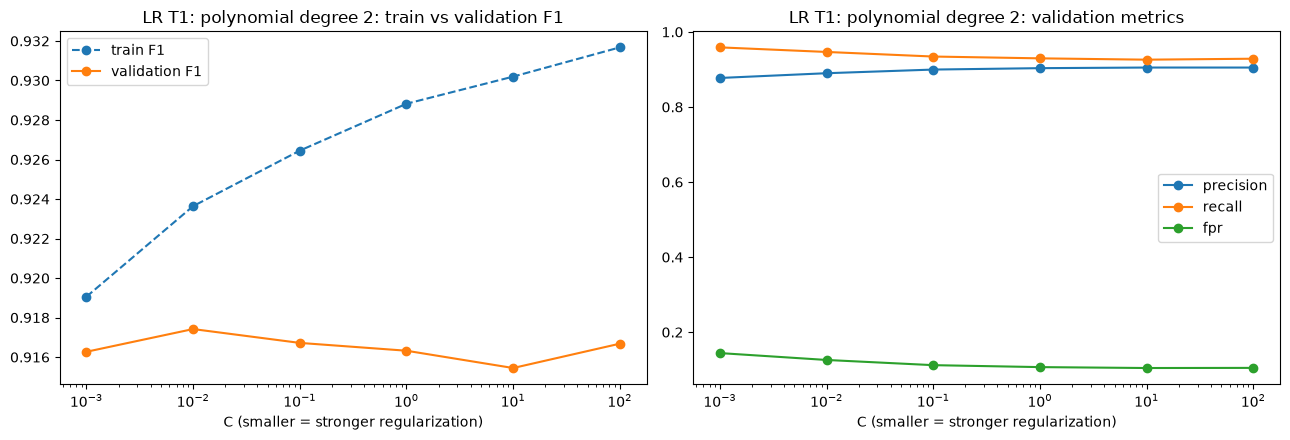

**Observed sweep:** from C=0.001 to C=100, training F1 changes from 0.9191 to 0.9317; validation F1 changes from 0.9163 to 0.9167. The train-minus-validation gap ranges from +0.0028 to +0.0150. FPR changes from 14.43% to 10.48%, while recall changes from 95.88% to 92.86%. Check both curves and the convergence flags before explaining this as a bias/variance trade-off. These differences come from one fixed validation split.

In [6]:
plot_sweep(results, "LR T1: polynomial degree 2", FIGS / "curve_lr_t1_poly2.png")
strongest, weakest = results.iloc[0], results.iloc[-1]
display(Markdown(
    f"**Observed sweep:** from C={strongest['value']:g} to C={weakest['value']:g}, "
    f"training F1 changes from {strongest['train_f1']:.4f} to {weakest['train_f1']:.4f}; "
    f"validation F1 changes from {strongest['val_f1']:.4f} to {weakest['val_f1']:.4f}. "
    f"The train-minus-validation gap ranges from {results['f1_gap'].min():+.4f} "
    f"to {results['f1_gap'].max():+.4f}. FPR changes from {strongest['val_fpr']:.2%} "
    f"to {weakest['val_fpr']:.2%}, while recall changes from "
    f"{strongest['val_recall']:.2%} to {weakest['val_recall']:.2%}. "
    "Check both curves and the convergence flags before explaining this as a "
    "bias/variance trade-off. These differences come from one fixed validation split."
))

**Interpretation of the recorded run.** All six settings converged on their first 2,000-iteration budget. Validation F1 peaks at **C=0.01 (0.9174)**, whereas training F1 increases from 0.9191 to 0.9317 across the grid. The F1 gap grows from 0.0028 to 0.0150. This is consistent with the larger quadratic basis fitting training-specific details under weaker regularization; it is not explained by a convergence warning in this run. The validation differences are small and fluctuate, so this is a descriptive pattern rather than proof of a statistically reliable advantage for one C.

We select C by F1, not by minimum FPR alone. Larger C reduces false alarms but also reduces recall, illustrating the operational trade-off in the right graph. Because the F1 winner lies inside the grid, the current sweep already brackets a useful regularization region. A later refinement can use cross-validation within training rather than repeatedly tuning to the same validation set. These statements describe the saved run; refresh them if the split or settings change.

**6. Select the best converged C**

Select the largest validation F1 among converged fits, as the reference does for
its successful fits. Exact ties use the first row in the ascending grid, preferring
stronger regularization. No test metrics or attack-type recall are used to select C.
An edge winner merits a possible wider grid; it does not guarantee improvement.
The selected validation F1 is a model-selection score, not an untouched test score.

The code reports the selected precision/recall/FPR and checks the fitted pipeline
on a few validation rows: its Z-space remains 2,774 columns and contains finite
values. This check uses `transform()`, never another `fit()`.

In [7]:
eligible = results[results["converged"]]
if eligible.empty:
    raise RuntimeError("No converged fit. The six-row CSV is saved; review optimization before selecting C.")
best = eligible.loc[eligible["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"Best C={best['value']:g}: val F1={best['val_f1']:.4f}, "
      f"precision={best['val_precision']:.4f}, recall={best['val_recall']:.4f}, "
      f"FPR={best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("Best C is at the edge: consider a wider grid as a follow-up experiment.")
Z_val_check = best_model[:-1].transform(X_val.iloc[:4])
assert Z_val_check.shape == (4, 2774) and np.isfinite(Z_val_check).all()
print("Verified model-input shapes: train (24000, 2774), validation (6000, 2774).")
print("Training sample counts in fitted scalers: 24,000; validation rows were not fitted.")

Best C=0.01: val F1=0.9174, precision=0.8900, recall=0.9466, FPR=0.1260
Verified model-input shapes: train (24000, 2774), validation (6000, 2774).
Training sample counts in fitted scalers: 24,000; validation rows were not fitted.


**Validation confusion matrix**

The graph's rows are true labels and its columns are predictions. Top-right counts
normal flows incorrectly flagged as attacks (FP); bottom-left counts missed attacks
(FN). This explains why F1 alone can hide an unacceptable false-alarm burden.

$$\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2TP}{2TP+FP+FN},\quad
\mathrm{FPR}=\frac{FP}{FP+TN}.$$

The caption below gives the actual counts and denominators. FPR is conditional on
normal traffic; expected false alarms equal FPR times the number of normal flows.

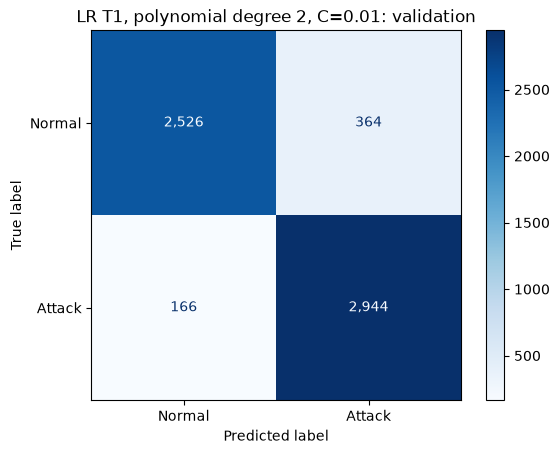

The selected model makes **364 false alarms** among 2,890 normal flows (FPR 12.60%) and misses **166 attacks** among 3,110 attacks (5.34%). Quadratic features can model interactions but do not guarantee separation of conflicting or overlapping traffic records.

In [8]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",",
)
plt.title(f"LR T1, polynomial degree 2, C={best['value']:g}: validation")
plt.savefig(FIGS / "confusion_lr_t1_poly2.png", dpi=150, bbox_inches="tight")
plt.show()
tn, fp, fn, tp = confusion_matrix(y_val, pred_val, labels=[0, 1]).ravel()
display(Markdown(
    f"The selected model makes **{fp:,} false alarms** among {tn + fp:,} normal "
    f"flows (FPR {fp / (tn + fp):.2%}) and misses **{fn:,} attacks** among "
    f"{tp + fn:,} attacks ({fn / (tp + fn):.2%}). "
    "Quadratic features can model interactions but do not guarantee separation "
    "of conflicting or overlapping traffic records."
))

**Attack-type recall: where do errors concentrate?**

`attack_recall()` groups validation predictions by metadata `attack_cat` and
returns the number of examples, caught attacks, missed attacks and recall.
The table is sorted by recall. Compare absolute misses as well: a common type
can dominate errors even if its recall exceeds that of a rare type. The EDA
motivates inspecting Fuzzers, but the actual table determines the findings.
Small groups such as Worms provide imprecise estimates, even at 100% recall.

In [9]:
by_attack = attack_recall(y_val, pred_val, cat_val)
display(by_attack)
most_missed = by_attack["missed"].idxmax()
display(Markdown(
    f"**{most_missed}** accounts for the largest number of misses: "
    f"{int(by_attack.loc[most_missed, 'missed'])} of "
    f"{int(by_attack['missed'].sum())} missed attacks. "
    "This breakdown can guide later feature experiments, but it is validation "
    "analysis and must not be treated as a final test result."
))

,rows,caught,missed,recall
type,,,,
Fuzzers,899,758,141,0.843
Analysis,89,83,6,0.933
Shellcode,61,60,1,0.984
Reconnaissance,419,414,5,0.988
Exploits,1105,1094,11,0.990
DoS,212,211,1,0.995
Generic,233,232,1,0.996
Backdoor,85,85,0,1.000
Worms,7,7,0,1.000


**Fuzzers** accounts for the largest number of misses: 141 of 166 missed attacks. This breakdown can guide later feature experiments, but it is validation analysis and must not be treated as a final test result.

**Which expanded features does the selected model use?**

The following table pairs the largest absolute coefficients with the polynomial
feature names, so interactions can be read in terms of the original preprocessed
columns. After the final scaler, a coefficient describes one training-standard-
deviation change in an expanded term; positive values increase attack log-odds.

This is not causal importance. Polynomial columns are correlated, some are
identical, and interactions cannot necessarily vary independently of their parent
features. TTL-related terms may retain lab shortcuts, so a later TTL-removal
experiment is still needed to assess reliance on them.

In [10]:
fitted_prep = best_model.named_steps["columntransformer"]
fitted_poly = best_model.named_steps["polynomialfeatures"]
expanded_names = fitted_poly.get_feature_names_out(fitted_prep.get_feature_names_out())
weights = best_model.named_steps["logisticregression"].coef_[0]
assert len(expanded_names) == len(weights) == 2774
coefficient_table = pd.DataFrame({"feature": expanded_names, "coefficient": weights})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
with pd.option_context("display.max_colwidth", 110):
    display(coefficient_table.nlargest(15, "absolute_coefficient").round(4))

,feature,coefficient,absolute_coefficient
1227,cat__service_http num__sttl,0.4853,0.4853
2696,log__ct_dst_src_ltm^2,0.3803,0.3803
2647,log__ct_state_ttl num__sttl,-0.2435,0.2435
66,num__sttl,0.2356,0.2356
2361,log__dloss num__sttl,-0.2255,0.2255
2578,log__dmean num__dttl,0.2160,0.2160
1822,cat__state_FIN num__dttl,0.2129,0.2129
1812,cat__state_FIN log__ct_state_ttl,0.2117,0.2117
2621,log__ct_srv_src^2,0.2109,0.2109
140,cat__proto_tcp num__dttl,0.2030,0.2030


**Comparison with the saved LR runs**

For context, the next block reads any existing T0, T2 and T3 result CSVs, selects
each one's best converged validation F1, and places it beside this T1 run. It does
not refit or change those experiments. Missing reference files are simply skipped.

Interpret this as a saved-run comparison assuming the same shared split files;
software versions and timing conditions can differ. A small difference on one
validation split is not evidence of statistical significance. Selection across
many configurations also makes validation scores optimistic relative to an
untouched final test. T1's extra scaler is part of its representation.

In [11]:
comparison_rows = []
for label, filename in [
    ("T0: shared baseline", "lr_t0.csv"),
    ("T1: polynomial degree 2", "lr_t1_poly2.csv"),
    ("T2: PCA 95%", "lr_t2_pca.csv"),
    ("T3: PCA(15) + polynomial degree 3", "lr_t3_pca_poly3.csv"),
]:
    path = RESULTS / filename
    if not path.is_file():
        print("Reference file unavailable:", filename)
        continue
    recorded = results if filename == "lr_t1_poly2.csv" else pd.read_csv(path)
    candidates = recorded[recorded["converged"]]
    if candidates.empty:
        continue
    winner = candidates.loc[candidates["val_f1"].idxmax()]
    comparison_rows.append({"representation": label, "best_C": winner["value"],
                            **{metric: winner[metric] for metric in
                               ["val_precision", "val_recall", "val_f1", "val_fpr"]}})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
if (comparison["representation"] == "T0: shared baseline").any():
    baseline_f1 = comparison.loc[comparison["representation"] == "T0: shared baseline", "val_f1"].iloc[0]
    display(Markdown(
        f"Selected T1 minus recorded T0 validation F1: **{best['val_f1'] - baseline_f1:+.4f}**. "
        "Use the precision/recall/FPR columns and attack-type analysis alongside this "
        "difference; it is not an estimate of deployment improvement."
    ))

,representation,best_C,val_precision,val_recall,val_f1,val_fpr
0,T0: shared baseline,100.00,0.8831,0.9473,0.9141,0.1349
1,T1: polynomial degree 2,0.01,0.8900,0.9466,0.9174,0.1260
2,T2: PCA 95%,100.00,0.8698,0.9322,0.8999,0.1502
3,T3: PCA(15) + polynomial degree 3,1.00,0.8971,0.9395,0.9179,0.1159


Selected T1 minus recorded T0 validation F1: **+0.0034**. Use the precision/recall/FPR columns and attack-type analysis alongside this difference; it is not an estimate of deployment improvement.

**7. Save and verify the six-row results CSV**

Write `results/lr_t1_poly2.csv`, labelled `model="LR"`, `transformation="T1"`,
`param="C"`. It uses the reference evaluator's schema plus `f1_gap`, matching
T2 and T3. The table stores every C and its final convergence flag, not only the
selected model. Reloading checks that the CSV has six unique C settings, finite
metrics and the same F1 values as the in-memory results.

The sweep and confusion-matrix figures use T1-specific filenames. Expanded
feature matrices and fitted pipelines are not serialized: they can be large,
while running this notebook regenerates them from the common split files.

In [12]:
output_path = RESULTS / "lr_t1_poly2.csv"
results.to_csv(output_path, index=False)
reloaded = pd.read_csv(output_path)
assert len(reloaded) == 6 and reloaded["value"].tolist() == GRID
assert set(reloaded["model"]) == {"LR"} and set(reloaded["transformation"]) == {"T1"}
assert set(reloaded["param"]) == {"C"}
metric_columns = [name for name in reloaded if name.startswith(("train_", "val_"))]
assert np.isfinite(reloaded[metric_columns].to_numpy()).all()
assert reloaded[metric_columns].apply(lambda column: column.between(0, 1).all()).all()
assert np.allclose(reloaded["val_f1"], results["val_f1"], rtol=0, atol=1e-12)
reference_csv = RESULTS / "lr_t2_pca.csv"
if reference_csv.is_file():
    assert reloaded.columns.tolist() == pd.read_csv(reference_csv, nrows=0).columns.tolist()
print("Saved and verified", len(reloaded), "rows:", output_path)
print("Plots:", FIGS / "curve_lr_t1_poly2.png", "and", FIGS / "confusion_lr_t1_poly2.png")
print("Converged settings:", int(reloaded["converged"].sum()), "of 6")

Saved and verified 6 rows: /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/verification/lr_t1_cleanup_2026-11-27/runs/baseline_default/workspace/results/lr_t1_poly2.csv
Plots: /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/verification/lr_t1_cleanup_2026-11-27/runs/baseline_default/workspace/figures/curve_lr_t1_poly2.png and /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/verification/lr_t1_cleanup_2026-11-27/runs/baseline_default/workspace/figures/confusion_lr_t1_poly2.png
Converged settings: 6 of 6


In [13]:
_verification_hooks.capture(globals())

VERIFIED six fits, all transformed values by streaming hashes, independent metrics and core plot data; best C=0.01.
